# VAR & CVAR

**Abraham Flores**  
Ingeniería Financiera · ITESO  
Simulación de Procesos Financieros

En este ejercicio se comparan tres formas de invertir un capital de 100,000 en AAPL, MSFT y NVDA. La idea es simular sus precios a un año y revisar cómo cambia la ganancia o pérdida del portafolio según los pesos elegidos.

Además del promedio, se revisan los cuartiles, el VaR y el CVaR. Me interesa especialmente la parte izquierda de las distribuciones, porque ahí quedan los escenarios menos favorables.

## Importación de bibliotecas

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import yfinance as yf

## 1. Precios históricos y rendimientos

Se descargan los precios de las tres acciones entre el 4 de noviembre de 2025 y el 4 de noviembre de 2026. Con ellos se calculan los rendimientos logarítmicos diarios y su matriz de covarianza.

La covarianza ayuda a identificar si los activos suelen moverse en la misma dirección. Esto es importante porque el resultado de un portafolio depende tanto del comportamiento de cada acción como de la relación entre ellas.

In [2]:
ticker = ['AAPL', 'MSFT', 'NVDA']
prices = yf.download(ticker, start='2025-11-04', end='2026-11-04')['Close']
Rendimientos_Logaritmicos = np.log(prices / prices.shift(1)).dropna()
Covarianza = Rendimientos_Logaritmicos.cov()
Covarianza

[*********************100%***********************]  3 of 3 completed


Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,0.000235,0.000036,0.000023
MSFT,0.000036,0.000425,0.000126
NVDA,0.000023,0.000126,0.000548


## 2. Simulación de precios

Se generan 10,000 escenarios para un horizonte de un año. Primero se construyen los choques aleatorios con la descomposición de Cholesky y después se estiman los precios finales de cada acción.

Para las tres estrategias se utilizan los mismos precios simulados. Así, la comparación se concentra en los pesos del portafolio y no en haber generado escenarios diferentes para cada caso.

In [3]:
T = 1
M = 10000
N_Act = len(prices.columns)

L = np.linalg.cholesky(Covarianza)
E = np.random.normal(0, 1, size = (N_Act, M))
Z = 0 + L @ E
Z = Z.T

In [4]:
ST = np.zeros(shape = (M, N_Act))
count = 0

for ticker in prices.columns:
    S0 = prices[ticker].iloc[-1]
    mu = Rendimientos_Logaritmicos[ticker].mean() * 252
    vol = Rendimientos_Logaritmicos[ticker].std() * np.sqrt(252)
    St = S0 * np.exp((mu - 0.5 * vol**2) * T + vol * np.sqrt(T) * Z[:, count])
    ST[:, count] = St
    count += 1

ST

array([[396.12650188, 507.1236416 , 203.01474162],
       [398.56897464, 507.21856345, 200.28895718],
       [398.41745203, 508.78118983, 202.63347928],
       ...,
       [396.78151954, 503.35844859, 201.40870575],
       [395.99538613, 502.92423104, 201.43268203],
       [399.0408594 , 504.95811615, 199.35847923]], shape=(10000, 3))

La matriz `ST` guarda los precios finales de las 10,000 simulaciones. Cada columna corresponde a una acción y cada fila representa un escenario posible al terminar el año.

## 3. Estrategia 1: solo AAPL

**Distribución del capital:** 100% AAPL; 0% MSFT; 0% NVDA.

El capital se destina a una sola acción, AAPL. Se calcula cuántas acciones enteras pueden comprarse y, con los precios simulados, se obtiene la ganancia o pérdida para cada escenario.

In [5]:
capital = 100000

w_1 = np.array([1, 0, 0])
values = capital*w_1
acciones = np.floor(values/prices.iloc[-1].values)
valor_port = np.sum(acciones*ST, axis=1)
PyG_1 = valor_port - capital

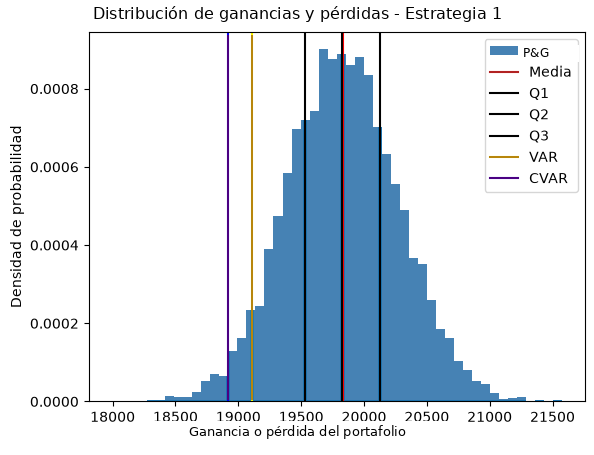

In [24]:
plt.figure(figsize=(10, 5))
plt.hist(PyG_1, bins=50, density=True, color='SteelBlue', alpha=1, label='Ganancia o pérdida')
media = PyG_1.mean()
q1 = np.quantile(PyG_1, 0.25)
q2 = np.quantile(PyG_1, 0.50)
q3 = np.quantile(PyG_1, 0.75)
var = np.percentile(PyG_1, 5)
cvar = np.mean(PyG_1[PyG_1 < var])
plt.xlabel('Ganancia o pérdida del portafolio')
plt.ylabel('Densidad de probabilidad')
plt.title('Distribución de ganancias y pérdidas de la Estrategia 1')
plt.axvline(media, color='FireBrick', linestyle='--', linewidth=1.8, label='Media')
plt.axvline(q1, color='DimGray', linestyle=':', linewidth=1.4, label='Q1')
plt.axvline(q2, color='Black', linestyle='-', linewidth=1.4, label='Mediana')
plt.axvline(q3, color='DimGray', linestyle=':', linewidth=1.4, label='Q3')
plt.axvline(var, color='DarkGoldenRod', linestyle='--', linewidth=1.7, label='VaR (percentil 5)')
plt.axvline(cvar, color='Indigo', linestyle='--', linewidth=1.7, label='CVaR')
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()
print(f'VaR (5%): {var:,.2f}')
print(f'CVaR (5%): {cvar:,.2f}')

En esta primera distribución el promedio se encuentra lejos de cero, del lado de las ganancias. Sin embargo, toda la inversión depende del desempeño de AAPL. Que el promedio sea atractivo no significa que esa ganancia esté asegurada.

## 4. Estrategia 2: pesos casi iguales

**Distribución del capital:** 33% AAPL; 33% MSFT; 34% NVDA.

Ahora se reparte el capital casi por partes iguales. La intención es reducir la dependencia de una sola acción y observar cómo cambia la distribución al combinar los tres activos.

In [7]:
capital = 100000

w_2 = np.array([0.33, 0.33, 0.34])
values = capital*w_2
acciones = np.floor(values/prices.iloc[-1].values)
valor_port = np.sum(acciones*ST, axis=1)
PyG_2 = valor_port - capital

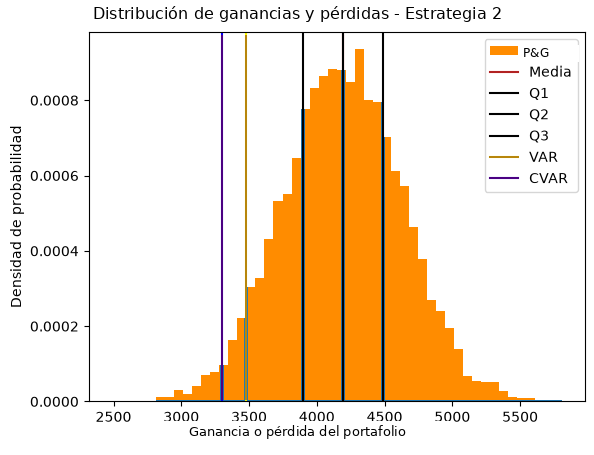

In [ ]:
plt.figure(figsize=(10, 5))
plt.hist(PyG_2, bins=50, density=True, color='DarkOrange', alpha=1, label='Ganancia o pérdida')
media = PyG_2.mean()
q1 = np.quantile(PyG_2, 0.25)
q2 = np.quantile(PyG_2, 0.50)
q3 = np.quantile(PyG_2, 0.75)
var = np.percentile(PyG_2, 5)
cvar = np.mean(PyG_2[PyG_2 < var])
plt.xlabel('Ganancia o pérdida del portafolio')
plt.ylabel('Densidad de probabilidad')
plt.title('Distribución de ganancias y pérdidas de la Estrategia 2')
plt.axvline(media, color='FireBrick', linestyle='--', linewidth=1.8, label='Media')
plt.axvline(q1, color='DimGray', linestyle=':', linewidth=1.4, label='Q1')
plt.axvline(q2, color='Black', linestyle='-', linewidth=1.4, label='Mediana')
plt.axvline(q3, color='DimGray', linestyle=':', linewidth=1.4, label='Q3')
plt.axvline(var, color='DarkGoldenRod', linestyle='--', linewidth=1.7, label='VaR (percentil 5)')
plt.axvline(cvar, color='Indigo', linestyle='--', linewidth=1.7, label='CVaR')
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()
print(f'VaR (5%): {var:,.2f}')
print(f'CVaR (5%): {cvar:,.2f}')

La distribución queda más concentrada que la de una inversión muy expuesta a un solo activo. Aun así, repartir el dinero no elimina por completo el riesgo, especialmente si las acciones se mueven de manera parecida.

## 5. Estrategia 3: mayor peso en NVDA

**Distribución del capital:** 20% AAPL; 20% MSFT; 60% NVDA.

En este último caso se da más importancia a NVDA, con 60% del capital. AAPL y MSFT conservan una participación menor. Se vuelve a calcular la ganancia o pérdida de los mismos 10,000 escenarios.

In [9]:
capital = 100000

w_3 = np.array([0.2, 0.2, 0.6])
values = capital*w_3
acciones = np.floor(values/prices.iloc[-1].values)
valor_port = np.sum(acciones*ST, axis=1)
PyG_3 = valor_port - capital

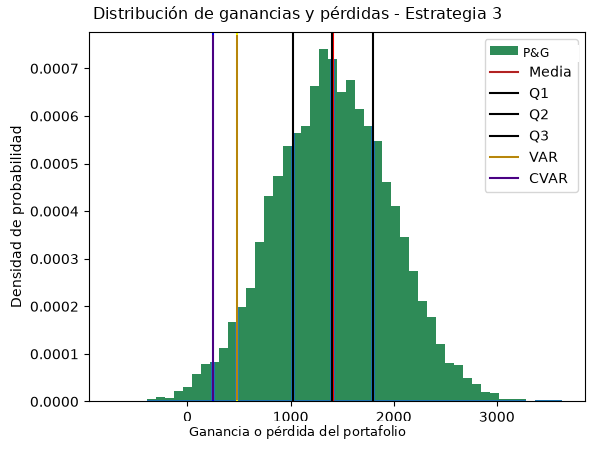

In [26]:
plt.figure(figsize=(10, 5))
plt.hist(PyG_3, bins=50, density=True, color='SeaGreen', alpha=1, label='Ganancia o pérdida')
media = PyG_3.mean()
q1 = np.quantile(PyG_3, 0.25)
q2 = np.quantile(PyG_3, 0.50)
q3 = np.quantile(PyG_3, 0.75)
var = np.percentile(PyG_3, 5)
cvar = np.mean(PyG_3[PyG_3 < var])
plt.xlabel('Ganancia o pérdida del portafolio')
plt.ylabel('Densidad de probabilidad')
plt.title('Distribución de ganancias y pérdidas de la Estrategia 3')
plt.axvline(media, color='FireBrick', linestyle='--', linewidth=1.8, label='Media')
plt.axvline(q1, color='DimGray', linestyle=':', linewidth=1.4, label='Q1')
plt.axvline(q2, color='Black', linestyle='-', linewidth=1.4, label='Mediana')
plt.axvline(q3, color='DimGray', linestyle=':', linewidth=1.4, label='Q3')
plt.axvline(var, color='DarkGoldenRod', linestyle='--', linewidth=1.7, label='VaR (percentil 5)')
plt.axvline(cvar, color='Indigo', linestyle='--', linewidth=1.7, label='CVaR')
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()
print(f'VaR (5%): {var:,.2f}')
print(f'CVaR (5%): {cvar:,.2f}')

Aquí la exposición a NVDA es mucho mayor. La cola izquierda se acerca más a la zona de pérdidas, por lo que conviene observar el VaR y el CVaR, no sólo la media. Tener tres acciones no garantiza una buena diversificación si una concentra la mayor parte del capital.

## 6. Comparación de resultados

Para revisar las tres estrategias juntas se comparan la ganancia media, la mediana y los resultados de la cola izquierda. También se calcula en qué porcentaje de escenarios el resultado termina por debajo de cero.

En este código, el VaR corresponde al percentil 5 de la ganancia o pérdida. El CVaR es el promedio de los resultados que quedan por debajo de ese punto. Por eso, si alguno es positivo, se está mostrando una ganancia en esa parte de la simulación, no un monto de pérdida.

In [ ]:
estrategias = {
    '1. Solo AAPL': PyG_1,
    '2. Pesos casi iguales': PyG_2,
    '3. Mayor peso en NVDA': PyG_3
}

resumen = []
for nombre, pyg in estrategias.items():
    var_5 = np.percentile(pyg, 5)
    cvar_5 = np.mean(pyg[pyg < var_5])
    resumen.append({
        'Estrategia': nombre,
        'Ganancia media': pyg.mean(),
        'Mediana': np.median(pyg),
        'VaR (P&G, 5%)': var_5,
        'CVaR (P&G, 5%)': cvar_5,
        'Prob. de pérdida (%)': 100 * np.mean(pyg < 0)
    })

comparacion = pd.DataFrame(resumen).set_index('Estrategia')
comparacion.round(2)

La tabla sirve para ver algo que no siempre queda claro con los histogramas: una estrategia puede tener una ganancia media mayor y, al mismo tiempo, resultados más expuestos a una sola acción. Para evaluar el riesgo vale más revisar también los escenarios desfavorables que quedarse únicamente con el promedio.

## 7. Conclusiones

Al comparar las tres estrategias, se nota que cambiar los pesos modifica bastante el resultado de la inversión. La primera depende totalmente de AAPL; la segunda reparte el capital entre los tres activos; y la tercera vuelve a concentrarlo, ahora principalmente en NVDA. Cada decisión cambia la forma de la distribución.

Me parece más útil revisar la media junto con el VaR y el CVaR que elegir el portafolio con la ganancia promedio más alta. La media resume lo que pasa en todos los escenarios, pero no deja ver por sí sola qué tan malos pueden ser los resultados de la cola izquierda.

También hay que considerar que el ejercicio utiliza un año de rendimientos históricos para simular el siguiente. Los resultados dependen de ese periodo y de los supuestos del modelo, así que no deben tomarse como ganancias o pérdidas garantizadas. La simulación ayuda a comparar estrategias, no a saber exactamente qué va a pasar.